# One-stage anchor-free detector (YOLO11, Ultralytics)

## 1. Setup

In [1]:
!pip -q install ultralytics pycocotools
import torch
print(torch.__version__, torch.cuda.is_available())

2.11.0+cu130 True


In [2]:
import os, subprocess, sys
from pathlib import Path

RUNS      = '/kaggle/working/runs'
DATA_ROOT = '/kaggle/working/data'
PREPARED  = '/tmp/yolo_dataset'             
REPO_URL  = 'https://github.com/vi-kibereva/ai-hw2.git'
SEED      = 42
os.makedirs(RUNS, exist_ok=True)

if not Path(DATA_ROOT, 'test_images.csv').exists():
    from kaggle_secrets import UserSecretsClient
    os.environ['KAGGLE_API_TOKEN'] = UserSecretsClient().get_secret('Homework2').strip()
    os.makedirs(DATA_ROOT, exist_ok=True)
    subprocess.run('kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p /tmp/ && '
                   f'unzip -oq /tmp/multiple-object-video-detection-hw-2-ucu-ai-2026.zip -d {DATA_ROOT} && '
                   'rm /tmp/multiple-object-video-detection-hw-2-ucu-ai-2026.zip', shell=True, check=True)

subprocess.run(f'rm -rf /kaggle/working/repo && git clone -q {REPO_URL} /kaggle/working/repo', shell=True, check=True)
sys.path.insert(0, '/kaggle/working/repo')
import scripts.eda as eda

100%|██████████| 9.88G/9.88G [01:14<00:00, 143MB/s] 


## 2. Data: clip-based split, subsampling and resolution from the EDA

In [3]:
eda.load_dataset.__defaults__ = (("train",),)     

eda.set_global_seed(eda.SEED)
_, objects, *_ = eda.load_tables(Path(DATA_ROOT))
decisions = eda.report_decisions(objects)           
IMGSZ, SMALL = decisions['imgsz'], decisions['small_frac']
STEP = eda.STEP or decisions['step']

if not Path(PREPARED, 'data.yaml').exists():
    eda.rebuild_dataset(Path(DATA_ROOT), PREPARED, STEP)   
print('data.yaml ->', f'{PREPARED}/data.yaml', '| imgsz', IMGSZ, '| step', STEP)

Object size after letterbox resize (tiny < 8 px, small < 16 px)
 imgsz  median_px  frac_tiny  frac_small
   640     15.196      0.098       0.542
   960     22.794      0.017       0.240
  1280     30.392      0.006       0.098
  1536     36.471      0.002       0.046
Optimal imgsz: 640
K-means anchors at imgsz=640 (w, h in input px; mean best IoU 0.73)
[[ 5.4  7.4]
 [ 6.7 13.6]
 [11.1  9.7]
 [ 9.7 19.2]
 [14.8 15.7]
 [20.8 11.4]
 [19.5 26.7]
 [32.3 17.8]
 [50.5 36.7]]
Frame similarity vs gap (same track_id)
 gap  persistence  mean_iou  median_iou
   1        0.993     0.851       0.897
   2        0.986     0.752       0.810
   3        0.979     0.676       0.731
   5        0.966     0.565       0.597
   8        0.946     0.457       0.440
  10        0.933     0.408       0.357
  15        0.901     0.328       0.203
  30        0.811     0.225       0.000
Best subsampling step: 3
Class imbalance: most/least frequent class ratio: 52x (car vs bus)
OK: every clip belongs to exactly 

## 3. Training helpers (same protocol for every experiment)

In [4]:
import torch
from ultralytics import YOLO

def patch_nwd(alpha, C=12.8):
    from ultralytics.utils import loss as L
    orig = L.bbox_iou

    def bbox_iou_nwd(box1, box2, xywh=True, GIoU=False, DIoU=False, CIoU=False, eps=1e-7):
        iou = orig(box1, box2, xywh=xywh, GIoU=GIoU, DIoU=DIoU, CIoU=CIoU, eps=eps)
        if not CIoU or xywh:                     
            return iou
        c1, c2 = (box1[..., :2] + box1[..., 2:]) / 2, (box2[..., :2] + box2[..., 2:]) / 2
        s1, s2 = (box1[..., 2:] - box1[..., :2]) / 2, (box2[..., 2:] - box2[..., :2]) / 2
        w2 = ((c1 - c2) ** 2).sum(-1) + ((s1 - s2) ** 2).sum(-1)
        nwd = torch.exp(-torch.sqrt(w2 + eps) / C).unsqueeze(-1)
        return (1 - alpha) * iou + alpha * nwd

    L.bbox_iou = bbox_iou_nwd
    print(f'[patch] box loss = (1-{alpha})*CIoU + {alpha}*NWD')
    return lambda: setattr(L, 'bbox_iou', orig)

WEIGHTS = {}                                     

def run(name, model='yolo11s.pt', imgsz=None, nwd=0.0, pretrained=None,
        epochs=30, batch=16, **overrides):
    cfg = eda.build_train_config(f'{PREPARED}/data.yaml', imgsz or IMGSZ, SMALL, seed=SEED)
    cfg.update(overrides)                         
    restore = patch_nwd(nwd) if nwd > 0 else None
    try:
        m = YOLO(model)
        if pretrained:
            m.load(pretrained)                    
        m.train(**cfg, epochs=epochs, batch=batch, project=RUNS, name=name,
                workers=4, patience=epochs, plots=True)
    finally:
        if restore:
            restore()                            
    WEIGHTS[name] = str(m.trainer.best)           
    return WEIGHTS[name]

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [5]:
import ultralytics
stock = (Path(ultralytics.__file__).parent / 'cfg/models/11/yolo11.yaml').read_text()
p2_head = '''# YOLO11 head with an extra P2/4 output
head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 6], 1, Concat, [1]]
  - [-1, 2, C3k2, [512, False]] # 13
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 2, C3k2, [256, False]] # 16 (P3)
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 2], 1, Concat, [1]]
  - [-1, 2, C3k2, [128, False]] # 19 (P2/4)
  - [-1, 1, Conv, [128, 3, 2]]
  - [[-1, 16], 1, Concat, [1]]
  - [-1, 2, C3k2, [256, False]] # 22 (P3)
  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 13], 1, Concat, [1]]
  - [-1, 2, C3k2, [512, False]] # 25 (P4)
  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 10], 1, Concat, [1]]
  - [-1, 2, C3k2, [1024, True]] # 28 (P5)
  - [[19, 22, 25, 28], 1, Detect, [nc]] # Detect(P2, P3, P4, P5)
'''
P2_YAML = '/kaggle/working/yolo11s-p2.yaml'
Path(P2_YAML).write_text(stock.split('# YOLO11n head')[0] + p2_head)

2172

## 4. Evaluation (COCO metrics on the validation clips; ignore regions are `iscrowd` boxes)

In [ ]:
import json, numpy as np, pandas as pd
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

CLASS_NAMES = eda.CLASS_NAMES
IMG_EXT = {'.jpg', '.jpeg', '.png'}

def build_val_gt(split='val'):
    root = Path(PREPARED); base = root / 'images' / split
    imgs = sorted(p for p in base.rglob('*') if p.suffix.lower() in IMG_EXT)
    d = {'info': {}, 'licenses': [], 'images': [], 'annotations': [],
         'categories': [{'id': i + 1, 'name': n} for i, n in enumerate(CLASS_NAMES)]}
    id2path, aid = {}, 1
    for i, p in enumerate(imgs, 1):
        W, H = Image.open(p).size
        rel = p.relative_to(base)
        d['images'].append({'id': i, 'file_name': rel.as_posix(), 'width': W, 'height': H})
        id2path[i] = str(p)
        lab = root / 'labels' / split / rel.with_suffix('.txt')
        ign = root / 'ignore' / split / rel.with_suffix('.txt')
        if lab.exists() and lab.stat().st_size:
            for c, cx, cy, w, h in np.loadtxt(lab, ndmin=2):
                d['annotations'].append({'id': aid, 'image_id': i, 'category_id': int(c) + 1, 'iscrowd': 0,
                    'bbox': [(cx - w / 2) * W, (cy - h / 2) * H, w * W, h * H], 'area': w * W * h * H})
                aid += 1
        if ign.exists() and ign.stat().st_size:
            for cx, cy, w, h in np.loadtxt(ign, ndmin=2):
                for k in range(1, len(CLASS_NAMES) + 1):     
                    d['annotations'].append({'id': aid, 'image_id': i, 'category_id': k, 'iscrowd': 1,
                        'bbox': [(cx - w / 2) * W, (cy - h / 2) * H, w * W, h * H], 'area': w * W * h * H})
                    aid += 1
    gt = COCO(); gt.dataset = d; gt.createIndex()
    return gt, id2path

def run_model(weights, paths, imgsz, conf=0.001, iou=0.6, max_det=300, bs=32):
    m, out, ms = YOLO(weights), {}, []
    for i in range(0, len(paths), bs):
        chunk = paths[i:i + bs]
        for p, r in zip(chunk, m.predict(chunk, imgsz=imgsz, conf=conf, iou=iou, max_det=max_det, verbose=False)):
            b = r.boxes
            out[p] = (b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int))
            ms.append(r.speed['inference'])
    return out, float(np.mean(ms))

def coco_eval(gt, dets, ids):
    ev = COCOeval(gt, gt.loadRes(dets), 'bbox')
    ev.params.imgIds = ids
    ev.params.maxDets = [1, 10, 300]
    ev.evaluate(); ev.accumulate()
    p = ev.eval['precision']                     
    def ap(area, iou=None):
        x = p[:, :, :, area, 2] if iou is None else p[iou, :, :, area, 2]
        x = x[x > -1]
        return float(x.mean()) if x.size else float('nan')
    return {'mAP': ap(0), 'AP50': ap(0, 0), 'AP75': ap(0, 5),
            'AP_small': ap(1), 'AP_medium': ap(2), 'AP_large': ap(3)}

RESULTS, GT = {}, None

def evaluate(name, weights, imgsz):
    global GT
    if GT is None:
        GT = build_val_gt()
    gt, id2path = GT
    ids = sorted(id2path)
    preds, ms = run_model(weights, [id2path[i] for i in ids], imgsz)
    dets = [{'image_id': i, 'category_id': int(c) + 1, 'score': float(s),
             'bbox': [float(x1), float(y1), float(x2 - x1), float(y2 - y1)]}
            for i in ids for (x1, y1, x2, y2), s, c in zip(*preds[id2path[i]])]
    RESULTS[name] = {**coco_eval(gt, dets, ids), 'ms_per_img': ms, 'imgsz': imgsz}
    json.dump(RESULTS, open(f'{RUNS}/results_anchor_free.json', 'w'), indent=2)
    return RESULTS[name]

## 5. Experiments
One change at a time; `epochs`, seed and data are the same for all runs.

In [7]:
# 1) baseline: YOLO11s at the resolution chosen in the EDA
evaluate('af_baseline', run('af_baseline', 'yolo11s.pt'), IMGSZ)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=af_baseline, nbs=64, nms=None, opset=None, optimize=False, op

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      6.39G      1.552     0.8941     0.9324        924        640: 100% ━━━━━━━━━━━━ 422/422 4.3it/s 1:39
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 3.4it/s 12.5s
                   all       1345      63952      0.416      0.336      0.308      0.142

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30       6.7G      1.518     0.8443     0.9224        543        640: 100% ━━━━━━━━━━━━ 422/422 4.2it/s 1:40
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 3.5it/s 12.4s
                   all       1345      63952      0.394      0.312      0.274      0.132

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      7.07G      1.479     0.8009     0.9129        712        640: 100% ━━━━━━━━━━━━ 422/422 4.2it/s 1:39
                 Class     Images  Instances      Box(

{'mAP': 0.13802594386004077,
 'AP50': 0.27899489361127355,
 'AP75': 0.12435065315292074,
 'AP_small': 0.07791898588884746,
 'AP_medium': 0.16584251463303298,
 'AP_large': 0.29395933335065355,
 'ms_per_img': 7.216541576208227,
 'imgsz': 640}

In [8]:
# 2) higher input resolution
evaluate('af_1280', run('af_1280', 'yolo11s.pt', imgsz=1280, batch=8), 1280)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=af_1280, nbs=64, nms=None, opset=None, optimize=False, optimi

{'mAP': 0.21884480867763176,
 'AP50': 0.4343126537198874,
 'AP75': 0.19345797659067906,
 'AP_small': 0.12378383470514771,
 'AP_medium': 0.2085433424895411,
 'AP_large': 0.29078762629105165,
 'ms_per_img': 29.928354530114976,
 'imgsz': 1280}

In [9]:
# 3) extra high-resolution P2 head (stride 4) for small objects
evaluate('af_p2', run('af_p2', P2_YAML, pretrained='yolo11s.pt', batch=8), IMGSZ)

Transferred 297/593 items from pretrained weights
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/yolo11s-p2.yaml, momentum=0.937, mosaic=1.0, multi_scale=0

{'mAP': 0.1324198301098389,
 'AP50': 0.2768277108084152,
 'AP75': 0.11460224828395416,
 'AP_small': 0.09641922088730479,
 'AP_medium': 0.14895942877229462,
 'AP_large': 0.2257442871003578,
 'ms_per_img': 10.967932804463302,
 'imgsz': 640}

In [10]:
# 4) loss modification: CIoU + NWD
evaluate('af_nwd', run('af_nwd', 'yolo11s.pt', nwd=0.5), IMGSZ)

[patch] box loss = (1-0.5)*CIoU + 0.5*NWD
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=af_nwd, nbs=64, nms

{'mAP': 0.14483959969225282,
 'AP50': 0.2846272837262174,
 'AP75': 0.1330822157344298,
 'AP_small': 0.07447850789434732,
 'AP_medium': 0.1538314807526099,
 'AP_large': 0.26782562693658524,
 'ms_per_img': 7.239618742744158,
 'imgsz': 640}

In [11]:
# 5) loss gains
evaluate('af_box10', run('af_box10', 'yolo11s.pt', box=10.0, cls=0.5), IMGSZ)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=10.0, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=af_box10, nbs=64, nms=None, opset=None, optimize=False, opti

{'mAP': 0.1455222090902727,
 'AP50': 0.29160971260286866,
 'AP75': 0.12774973837636341,
 'AP_small': 0.07039102063203662,
 'AP_medium': 0.14688007987310442,
 'AP_large': 0.269602484075119,
 'ms_per_img': 7.2465645152379565,
 'imgsz': 640}

## 6. Results

In [12]:
pd.DataFrame(RESULTS).T.round(4)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_img,imgsz
af_baseline,0.1380,0.2790,0.1244,0.0779,0.1658,0.2940,7.2165,640.0
af_1280,0.2188,0.4343,0.1935,0.1238,0.2085,0.2908,29.9284,1280.0
af_p2,0.1324,0.2768,0.1146,0.0964,0.1490,0.2257,10.9679,640.0
af_nwd,0.1448,0.2846,0.1331,0.0745,0.1538,0.2678,7.2396,640.0
af_box10,0.1455,0.2916,0.1277,0.0704,0.1469,0.2696,7.2466,640.0


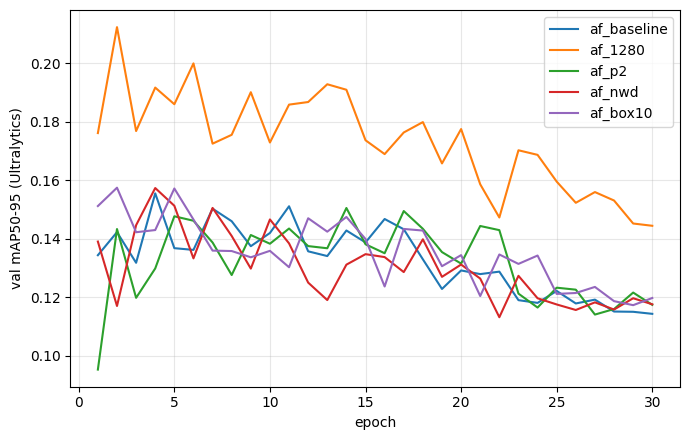

,run,best_epoch,best_mAP50-95,last_mAP50-95
0,af_baseline,4,0.1555,0.1143
1,af_1280,2,0.2124,0.1444
2,af_p2,14,0.1505,0.1174
3,af_nwd,4,0.1574,0.1176
4,af_box10,2,0.1575,0.1197


In [13]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4.5)); rows = []
for n in RESULTS:
    csv = Path(WEIGHTS[n]).parent.parent / 'results.csv'
    df = pd.read_csv(csv); df.columns = [c.strip() for c in df.columns]
    m = df['metrics/mAP50-95(B)']
    ax.plot(df['epoch'], m, label=n)
    rows.append({'run': n, 'best_epoch': int(m.idxmax()) + 1, 'best_mAP50-95': m.max(), 'last_mAP50-95': m.iloc[-1]})
ax.set_xlabel('epoch'); ax.set_ylabel('val mAP50-95 (Ultralytics)'); ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig('/kaggle/working/af_val_curves.png', dpi=130); plt.show()
pd.DataFrame(rows).round(4)

## 7. Test predictions (competition format: `class score x y w h`)

In [14]:
def make_submission(weights, out, imgsz=None, conf=0.25):
    df = pd.read_csv(f'{DATA_ROOT}/test_images.csv')
    m, rows = YOLO(weights), []
    kw = dict(conf=conf, verbose=False, **({'imgsz': imgsz} if imgsz else {}))
    for i in range(0, len(df), 32):
        part = df.iloc[i:i + 32]
        res = m.predict([f'{DATA_ROOT}/{f}' for f in part['file_name']], **kw)
        for iid, r in zip(part['image_id'], res):
            s = ' '.join(f'{int(c)} {v:.4f} {int(x1)} {int(y1)} {int(x2 - x1)} {int(y2 - y1)}'
                         for (x1, y1, x2, y2), v, c in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist(), r.boxes.cls.tolist()))
            rows.append({'image_id': iid, 'PredictionString': s})
    pd.DataFrame(rows).to_csv(out, index=False)
    print('wrote', out, len(rows), 'rows')